# Notebook de Preparação dos Dados para a Pipeline do Modelo

Este notebook reúne os passos necessários para explorar, organizar e preparar os dados de coordenadas das mãos capturados com o **HandLandmark do MediaPipe**.

Nosso objetivo é transformar essas coordenadas em um conjunto de dados consistente e bem estruturado, pronto para treinar modelos de **machine learning** capazes de classificar letras da **Libras** com maior precisão.

Ao longo do notebook, vamos seguir uma sequência clara de trabalho: entender a origem dos dados, inspecionar sua estrutura, tratar possíveis inconsistências e preparar tudo para a etapa de treinamento do modelo.

## Passo a passo 

1. **Carregar os dados**
   - Importar os arquivos ou tabelas com as coordenadas das mãos.
   - Verificar se os dados foram lidos corretamente.

2. **Entender a estrutura do conjunto de dados**
   - Conferir colunas, tipos de dados e quantidade de registros.
   - Identificar quais atributos representam os pontos da mão.

3. **Fazer uma análise inicial**
   - Verificar valores ausentes, dados duplicados e possíveis inconsistências.
   - Observar a distribuição das classes, como letras ou sinais.

4. **Limpar e organizar os dados**
   - Tratar valores nulos e remover duplicatas, se necessário.
   - Padronizar nomes de colunas e formatos.

5. **Engenharia de Features**
   - Calcular a distância euclidiana entre as pontas dos dedos e o pulso.

6. **Preparar as variáveis para o modelo**
   - Separar entrada e saída.
   - Manter as coordenadas e as novas distâncias como variáveis de entrada.

7. **Dividir os dados para treino e teste**
   - Criar conjuntos de treino, validação e teste.
   - Garantir que a divisão seja representativa.

8. **Salvar a versão final preparada**
   - Exportar o dataset tratado para uso na pipeline de treinamento.
   - Registrar decisões importantes tomadas durante a preparação.

### Imports 

In [34]:
# Imports
import json
from pathlib import Path

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid", palette="deep")

# Caminhos dos arquivos
# Funciona tanto se o notebook for executado a partir da raiz do projeto
# quanto se for executado de dentro da pasta notebooks/.
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
data_separated = PROJECT_ROOT / "data" / "data_separeted"
data_output = PROJECT_ROOT / "data" / "data_output"

RANDOM_STATE = 42
LABEL_COLUMN = "label"


## 1. **Carregar os dados**
   - Importar os arquivos ou tabelas com as coordenadas das mãos.
   - Verificar se os dados foram lidos corretamente.


In [35]:
def concat_tables(data_input, data_output):
    dfs = []

    for item in sorted(data_input.glob("*.csv")):
        df_temp = pd.read_csv(item)
        df_temp["source_file"] = item.name
        dfs.append(df_temp)

    if not dfs:
        raise FileNotFoundError(f"Nenhum arquivo CSV encontrado em {data_input}")

    df = pd.concat(dfs, ignore_index=True)

    data_output.mkdir(parents=True, exist_ok=True)
    output_file = data_output / "dataset_concatenado.csv"
    df.to_csv(output_file, index=False)

    return df


In [36]:
df = concat_tables(data_separated, data_output)
df.head()


,label,x0,y0,z0,x1,y1,z1,x2,y2,z2,...,x18,y18,z18,x19,y19,z19,x20,y20,z20,source_file
0,A,0.0,0.0,0.0,-0.279288,-0.165591,-0.079699,-0.521103,-0.502658,-0.117389,...,0.226257,-0.859783,-0.184327,0.174208,-0.622645,-0.131428,0.169268,-0.501116,-0.068995,datasetAMEP (1).csv
1,A,0.0,0.0,0.0,-0.230183,-0.162898,-0.086023,-0.429579,-0.515378,-0.107071,...,0.177663,-0.825861,-0.098269,0.129152,-0.638704,-0.045937,0.151294,-0.609237,0.011671,datasetAMEP (1).csv
2,A,0.0,0.0,0.0,-0.216314,-0.150896,-0.082746,-0.414731,-0.511850,-0.101263,...,0.175588,-0.827686,-0.092815,0.130033,-0.650662,-0.038147,0.156966,-0.628454,0.019171,datasetAMEP (1).csv
3,A,0.0,0.0,0.0,-0.221650,-0.154646,-0.086122,-0.424169,-0.509196,-0.106448,...,0.184436,-0.820161,-0.087063,0.137433,-0.646774,-0.034385,0.164424,-0.629382,0.020973,datasetAMEP (1).csv
4,A,0.0,0.0,0.0,-0.220164,-0.151683,-0.093979,-0.428585,-0.511275,-0.116125,...,0.182142,-0.832294,-0.085049,0.135735,-0.652420,-0.033953,0.161024,-0.638898,0.020778,datasetAMEP (1).csv


## 2. **Entender a estrutura do conjunto de dados**
   - Conferir colunas, tipos de dados e quantidade de registros.
   - Identificar quais atributos representam os pontos da mão.


In [37]:
landmark_columns = [col for col in df.columns if col != LABEL_COLUMN and col != "source_file"]
expected_landmark_columns = [f"{axis}{idx}" for idx in range(21) for axis in ("x", "y", "z")]
missing_landmark_columns = sorted(set(expected_landmark_columns) - set(landmark_columns))
extra_landmark_columns = sorted(set(landmark_columns) - set(expected_landmark_columns))

estrutura = pd.DataFrame(
    {
        "metrica": [
            "linhas",
            "colunas",
            "classes",
            "features_landmarks",
            "colunas_landmarks_ausentes",
            "colunas_landmarks_extras",
        ],
        "valor": [
            len(df),
            df.shape[1],
            df[LABEL_COLUMN].nunique(),
            len(landmark_columns),
            missing_landmark_columns,
            extra_landmark_columns,
        ],
    }
)

estrutura


,metrica,valor
0,linhas,27444
1,colunas,65
2,classes,20
3,features_landmarks,63
4,colunas_landmarks_ausentes,[]
5,colunas_landmarks_extras,[]


In [38]:
df.dtypes.value_counts()


float64    63
str         2
Name: count, dtype: int64

## 3. **Fazer uma análise inicial**
   - Verificar valores ausentes, dados duplicados e possíveis inconsistências.
   - Observar a distribuição das classes, como letras ou sinais.


In [39]:
qualidade = pd.DataFrame(
    {
        "metrica": [
            "valores_ausentes",
            "linhas_duplicadas",
            "labels_ausentes",
            "arquivos_origem",
        ],
        "valor": [
            int(df.isna().sum().sum()),
            int(df.duplicated().sum()),
            int(df[LABEL_COLUMN].isna().sum()),
            df["source_file"].nunique(),
        ],
    }
)

qualidade


,metrica,valor
0,valores_ausentes,0
1,linhas_duplicadas,0
2,labels_ausentes,0
3,arquivos_origem,6


In [40]:
class_counts = df[LABEL_COLUMN].value_counts().sort_index()
class_counts.to_frame("quantidade")


,quantidade
label,
A,1883
B,1100
C,1025
D,1007
E,1140
F,2698
G,1008
I,1003
L,1222


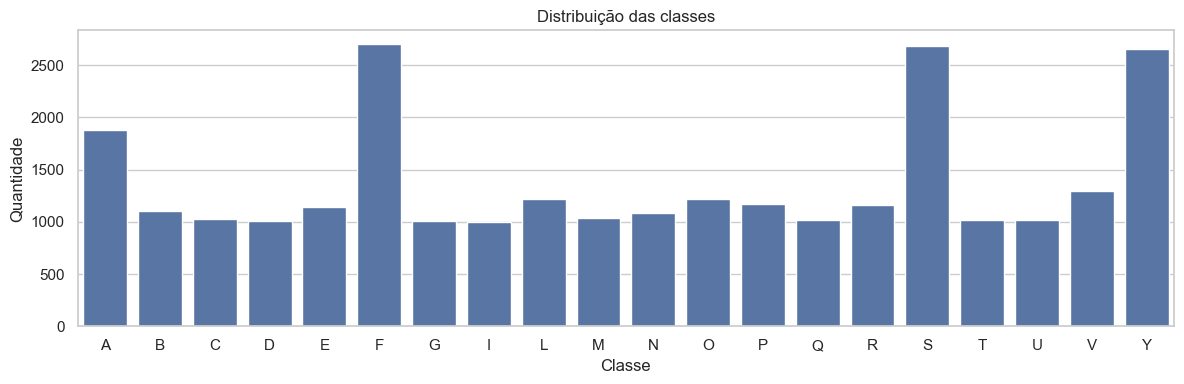

In [41]:
plt.figure(figsize=(12, 4))
sns.countplot(data=df, x=LABEL_COLUMN, order=class_counts.index)
plt.title("Distribuição das classes")
plt.xlabel("Classe")
plt.ylabel("Quantidade")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


## 4. **Limpar e organizar os dados**
   - Tratar valores nulos e remover duplicatas, se necessário.
   - Padronizar nomes de colunas e formatos.


In [42]:
def clean_dataset(df, label_column=LABEL_COLUMN):
    df_clean = df.copy()
    df_clean.columns = df_clean.columns.str.strip()

    df_clean[label_column] = (
        df_clean[label_column]
        .astype("string")
        .str.strip()
        .str.upper()
    )

    feature_columns = [col for col in df_clean.columns if col not in [label_column, "source_file"]]
    df_clean[feature_columns] = df_clean[feature_columns].apply(pd.to_numeric, errors="coerce")

    rows_before = len(df_clean)
    df_clean = df_clean.dropna(subset=[label_column, *feature_columns])
    df_clean = df_clean.reset_index(drop=True)

    cleaning_report = {
        "linhas_antes": rows_before,
        "linhas_depois": len(df_clean),
        "linhas_removidas": rows_before - len(df_clean),
        "valores_ausentes_restantes": int(df_clean[[label_column, *feature_columns]].isna().sum().sum()),
    }

    return df_clean, feature_columns, cleaning_report


df_clean, feature_columns, cleaning_report = clean_dataset(df)
cleaning_report


{'linhas_antes': 27444,
 'linhas_depois': 27444,
 'linhas_removidas': 0,
 'valores_ausentes_restantes': 0}

In [43]:
df_clean[LABEL_COLUMN].value_counts().sort_index().to_frame("quantidade")


,quantidade
label,
A,1883
B,1100
C,1025
D,1007
E,1140
F,2698
G,1008
I,1003
L,1222


## 5. **Engenharia de Features**
   - Calcular a distância euclidiana entre as pontas dos dedos e o pulso.

In [44]:
fingertips = {'polegar': 4, 'indicador': 8, 'medio': 12, 'anelar': 16, 'minimo': 20}
for name, idx in fingertips.items():
    col_name = f'dist_{name}_pulso'
    df_clean[col_name] = ((df_clean[f'x{idx}'] - df_clean['x0'])**2 + \
                         (df_clean[f'y{idx}'] - df_clean['y0'])**2 + \
                         (df_clean[f'z{idx}'] - df_clean['z0'])**2)**0.5
    feature_columns.append(col_name)
    pares_distancias = { # novas features para pegar agrupamentos especificos de Letras com representação muito próxima
    # R vs U / V
    "dist_indicador_medio_pontas": (8, 12),
    "dist_indicador_medio_pip": (6, 10),
    "dist_indicador_medio_mcp": (5, 9),

    # Y vs I
    "dist_polegar_minimo_pontas": (4, 20),
    "dist_polegar_indicador_pontas": (4, 8),

    # F vs T
    "dist_polegar_indicador_mcp": (4, 5),
    "dist_polegar_indicador_pip": (4, 6),
    "dist_polegar_indicador_dip": (4, 7),
    "dist_polegar_indicador_tip": (4, 8),

    # N vs M
    "dist_indicador_anelar_pontas": (8, 16),
    "dist_medio_anelar_pontas": (12, 16),
}

for col_name, (idx_a, idx_b) in pares_distancias.items():
    df_clean[col_name] = (
        (df_clean[f"x{idx_a}"] - df_clean[f"x{idx_b}"]) ** 2
        + (df_clean[f"y{idx_a}"] - df_clean[f"y{idx_b}"]) ** 2
        + (df_clean[f"z{idx_a}"] - df_clean[f"z{idx_b}"]) ** 2
    ) ** 0.5

    if col_name not in feature_columns:
        feature_columns.append(col_name)

## 6. **Preparar as variáveis para o modelo**
   - Separar entrada e saída.
   - Manter as coordenadas e as novas distâncias como variáveis de entrada.


In [45]:
X = df_clean[feature_columns]
y = df_clean[LABEL_COLUMN]

print(f"X: {X.shape}")
print(f"y: {y.shape}")
print(f"Classes: {sorted(y.unique())}")


X: (27444, 79)
y: (27444,)
Classes: ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'I', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'Y']


## 7. **Dividir os dados para treino, validação e teste**
   - Criar conjuntos estratificados por classe e origem, usando blocos contíguos para reduzir vazamento entre frames vizinhos.
   - Calcular estatísticas de padronização usando apenas o treino.


In [46]:
def block_stratified_split(
    df,
    label_column=LABEL_COLUMN,
    source_column="source_file",
    test_size=0.15,
    val_size=0.15,
    purge_gap=5,
    random_state=RANDOM_STATE,
):
    """Split em blocos contíguos por classe/origem para evitar leakage temporal.

    O purge_gap remove algumas linhas nas bordas entre splits. Isso evita que frames
    quase idênticos, imediatamente vizinhos na captura, caiam em conjuntos diferentes.
    """
    if label_column not in df.columns:
        raise KeyError(f"Coluna de label não encontrada: {label_column}")

    group_columns = [label_column]
    if source_column in df.columns:
        group_columns.append(source_column)

    train_parts = []
    val_parts = []
    test_parts = []

    train_size = 1 - val_size - test_size
    if train_size <= 0:
        raise ValueError("A soma de val_size e test_size precisa ser menor que 1.")

    for _, group in df.groupby(group_columns, sort=False):
        group = group.sort_index()
        n_rows = len(group)
        train_end = round(n_rows * train_size)
        val_end = round(n_rows * (train_size + val_size))

        effective_gap = purge_gap if n_rows >= (4 * purge_gap + 10) else 0

        train_parts.append(group.iloc[: max(train_end - effective_gap, 0)])
        val_parts.append(group.iloc[min(train_end + effective_gap, n_rows) : max(val_end - effective_gap, train_end + effective_gap)])
        test_parts.append(group.iloc[min(val_end + effective_gap, n_rows) :])

    train = pd.concat(train_parts)
    val = pd.concat(val_parts)
    test = pd.concat(test_parts)

    return (
        train.sample(frac=1, random_state=random_state).reset_index(drop=True),
        val.sample(frac=1, random_state=random_state).reset_index(drop=True),
        test.sample(frac=1, random_state=random_state).reset_index(drop=True),
    )


df_model = df_clean.drop_duplicates(subset=[LABEL_COLUMN, *feature_columns]).reset_index(drop=True)
train_df, val_df, test_df = block_stratified_split(df_model)

split_summary = pd.DataFrame(
    {
        "split": ["treino", "validacao", "teste"],
        "linhas": [len(train_df), len(val_df), len(test_df)],
        "percentual": [len(train_df) / len(df_model), len(val_df) / len(df_model), len(test_df) / len(df_model)],
    }
)

split_summary

,split,linhas,percentual
0,treino,19102,0.696036
1,validacao,3896,0.141962
2,teste,4006,0.145970


In [47]:
pd.concat(
    {
        "treino": train_df[LABEL_COLUMN].value_counts(normalize=True).sort_index(),
        "validacao": val_df[LABEL_COLUMN].value_counts(normalize=True).sort_index(),
        "teste": test_df[LABEL_COLUMN].value_counts(normalize=True).sort_index(),
    },
    axis=1,
).fillna(0).round(4)


,treino,validacao,teste
label,,,
A,0.0685,0.0675,0.0679
B,0.04,0.0398,0.0399
C,0.0373,0.0367,0.0372
D,0.0366,0.0362,0.0364
E,0.0415,0.0413,0.0414
F,0.0986,0.1011,0.0999
G,0.0367,0.0362,0.0364
I,0.0365,0.0362,0.0362
L,0.0445,0.0447,0.0444


In [48]:
def standardize_splits(train_df, val_df, test_df, feature_columns):
    train_mean = train_df[feature_columns].mean()
    train_std = train_df[feature_columns].std().replace(0, 1)

    def transform(split_df):
        split_scaled = split_df.copy()
        split_scaled[feature_columns] = (split_scaled[feature_columns] - train_mean) / train_std
        return split_scaled

    scaler_stats = pd.DataFrame(
        {
            "feature": feature_columns,
            "mean": train_mean.values,
            "std": train_std.values,
        }
    )

    return transform(train_df), transform(val_df), transform(test_df), scaler_stats


train_scaled, val_scaled, test_scaled, scaler_stats = standardize_splits(
    train_df,
    val_df,
    test_df,
    feature_columns,
)

train_scaled.head()


,label,x0,y0,z0,x1,y1,z1,x2,y2,z2,...,dist_indicador_medio_pip,dist_indicador_medio_mcp,dist_polegar_minimo_pontas,dist_polegar_indicador_pontas,dist_polegar_indicador_mcp,dist_polegar_indicador_pip,dist_polegar_indicador_dip,dist_polegar_indicador_tip,dist_indicador_anelar_pontas,dist_medio_anelar_pontas
0,F,0.0,0.0,0.0,-0.677623,-0.301028,0.317427,-0.567458,-0.373401,0.533034,...,0.504473,0.051890,0.024555,-1.577269,-1.224346,-1.144886,-1.411355,-1.577269,0.211346,-0.383229
1,A,0.0,0.0,0.0,-1.250467,0.441103,-1.845972,-1.426928,-0.209762,-1.761458,...,0.254906,1.620718,1.351806,0.575799,1.244096,1.304333,0.856537,0.575799,-0.463513,-0.148992
2,O,0.0,0.0,0.0,-1.255528,-0.228857,0.756359,-0.964644,-0.273885,0.576929,...,-1.451722,-1.867114,-1.227714,-1.184404,1.786885,0.779503,-0.249785,-1.184404,-1.640042,-0.824661
3,L,0.0,0.0,0.0,-0.482106,0.286116,-0.041535,-0.654397,0.135690,-0.155060,...,0.860101,-0.432978,0.280166,1.676083,0.810498,1.240257,1.625535,1.676083,1.218623,-0.655175
4,O,0.0,0.0,0.0,-1.282456,0.520329,1.102954,-1.334052,0.307999,1.042759,...,-0.344083,-0.183919,-0.755108,-1.602388,0.634172,0.347592,-0.707011,-1.602388,-1.476490,-0.757466


## 8. **Salvar a versão final preparada**
   - Exportar o dataset tratado para uso na pipeline de treinamento.
   - Registrar decisões importantes tomadas durante a preparação.


In [49]:
prepared_output = data_output / "prepared"
prepared_output.mkdir(parents=True, exist_ok=True)

df_clean.to_csv(prepared_output / "dataset_limpo.csv", index=False)
train_scaled.to_csv(prepared_output / "train.csv", index=False)
val_scaled.to_csv(prepared_output / "validation.csv", index=False)
test_scaled.to_csv(prepared_output / "test.csv", index=False)
scaler_stats.to_csv(prepared_output / "standardization_stats.csv", index=False)

metadata = {
    "label_column": LABEL_COLUMN,
    "feature_columns": feature_columns,
    "classes": sorted(df_clean[LABEL_COLUMN].unique().tolist()),
    "random_state": RANDOM_STATE,
    "split_strategy": "block_stratified_by_label_and_source_file",
    "purge_gap_rows": 5,
    "split_rows": {
        "train": len(train_scaled),
        "validation": len(val_scaled),
        "test": len(test_scaled),
    },
    "cleaning_report": cleaning_report,
    "outputs": {
        "clean_dataset": str(prepared_output / "dataset_limpo.csv"),
        "train": str(prepared_output / "train.csv"),
        "validation": str(prepared_output / "validation.csv"),
        "test": str(prepared_output / "test.csv"),
        "standardization_stats": str(prepared_output / "standardization_stats.csv"),
    },
}

with (prepared_output / "metadata.json").open("w", encoding="utf-8") as file:
    json.dump(metadata, file, indent=2, ensure_ascii=False)

metadata


{'label_column': 'label',
 'feature_columns': ['x0',
  'y0',
  'z0',
  'x1',
  'y1',
  'z1',
  'x2',
  'y2',
  'z2',
  'x3',
  'y3',
  'z3',
  'x4',
  'y4',
  'z4',
  'x5',
  'y5',
  'z5',
  'x6',
  'y6',
  'z6',
  'x7',
  'y7',
  'z7',
  'x8',
  'y8',
  'z8',
  'x9',
  'y9',
  'z9',
  'x10',
  'y10',
  'z10',
  'x11',
  'y11',
  'z11',
  'x12',
  'y12',
  'z12',
  'x13',
  'y13',
  'z13',
  'x14',
  'y14',
  'z14',
  'x15',
  'y15',
  'z15',
  'x16',
  'y16',
  'z16',
  'x17',
  'y17',
  'z17',
  'x18',
  'y18',
  'z18',
  'x19',
  'y19',
  'z19',
  'x20',
  'y20',
  'z20',
  'dist_polegar_pulso',
  'dist_indicador_pulso',
  'dist_medio_pulso',
  'dist_anelar_pulso',
  'dist_minimo_pulso',
  'dist_indicador_medio_pontas',
  'dist_indicador_medio_pip',
  'dist_indicador_medio_mcp',
  'dist_polegar_minimo_pontas',
  'dist_polegar_indicador_pontas',
  'dist_polegar_indicador_mcp',
  'dist_polegar_indicador_pip',
  'dist_polegar_indicador_dip',
  'dist_polegar_indicador_tip',
  'dist_indi